# Supplementary Figure S9h. Donor-level cell fractions used for cell-proportion QTL mapping

Left: distribution of donor-level cell fractions (426 donors) of the six major brain cell types used as phenotypes in cell-proportion-QTL mapping, drawn as 30-bin histograms with free axes per cell type. To avoid sharing individual-level data, only the aggregated bin counts (the bins drawn by the original `geom_histogram(bins = 30)`) and per-cell-type summary statistics (mean, SD, 5/25/50/75/95% quantiles) are provided. Right: number of cell-proportion-QTL credible sets (CS50 fine-mapping summary, unique identifiers with `cs_50 != 0`) per cell type. Descriptive; no statistical test.

Input: `data/Figure_S9h_cell_fraction.rds`

In [1]:
library(ggplot2)
library(patchwork)
res <- readRDS("data/Figure_S9h_cell_fraction.rds")
res$summary
res$propQTL_cs
head(res$histogram)

cell_type,n_donors,mean,sd,q05,q25,median,q75,q95
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ast,426,0.14100004,0.03224229,0.09651477,0.12413712,0.13931691,0.15722128,0.19540313
Mic,426,0.05121478,0.01862772,0.02396091,0.03981539,0.04977370,0.05981383,0.08225160
Exc,426,0.39174090,0.06627790,0.28460008,0.35915948,0.39516686,0.42650812,0.48345136
Inh,426,0.15488093,0.03106949,0.10642394,0.13719699,0.15582568,0.17196687,0.20447288
OPC,426,0.03930662,0.01203403,0.02626545,0.03284689,0.03729757,0.04305366,0.05769044
Oli,426,0.20827148,0.06623645,0.11737610,0.16852762,0.19798053,0.24381689,0.32559782


cell_type,n_cs
<fct>,<int>
Mic,32
Exc,27
Inh,32
Ast,36
Oli,31
OPC,65


,cell_type,bin_center,bin_min,bin_max,n_donors
,<fct>,<dbl>,<dbl>,<dbl>,<int>
1,Ast,0.01216443,0.007353206,0.01697565,1
2,Ast,0.02178688,0.016975653,0.02659810,2
3,Ast,0.03140932,0.026598101,0.03622055,1
4,Ast,0.04103177,0.036220548,0.04584300,2
5,Ast,0.05065422,0.045842995,0.05546544,0
6,Ast,0.06027667,0.055465443,0.06508789,1


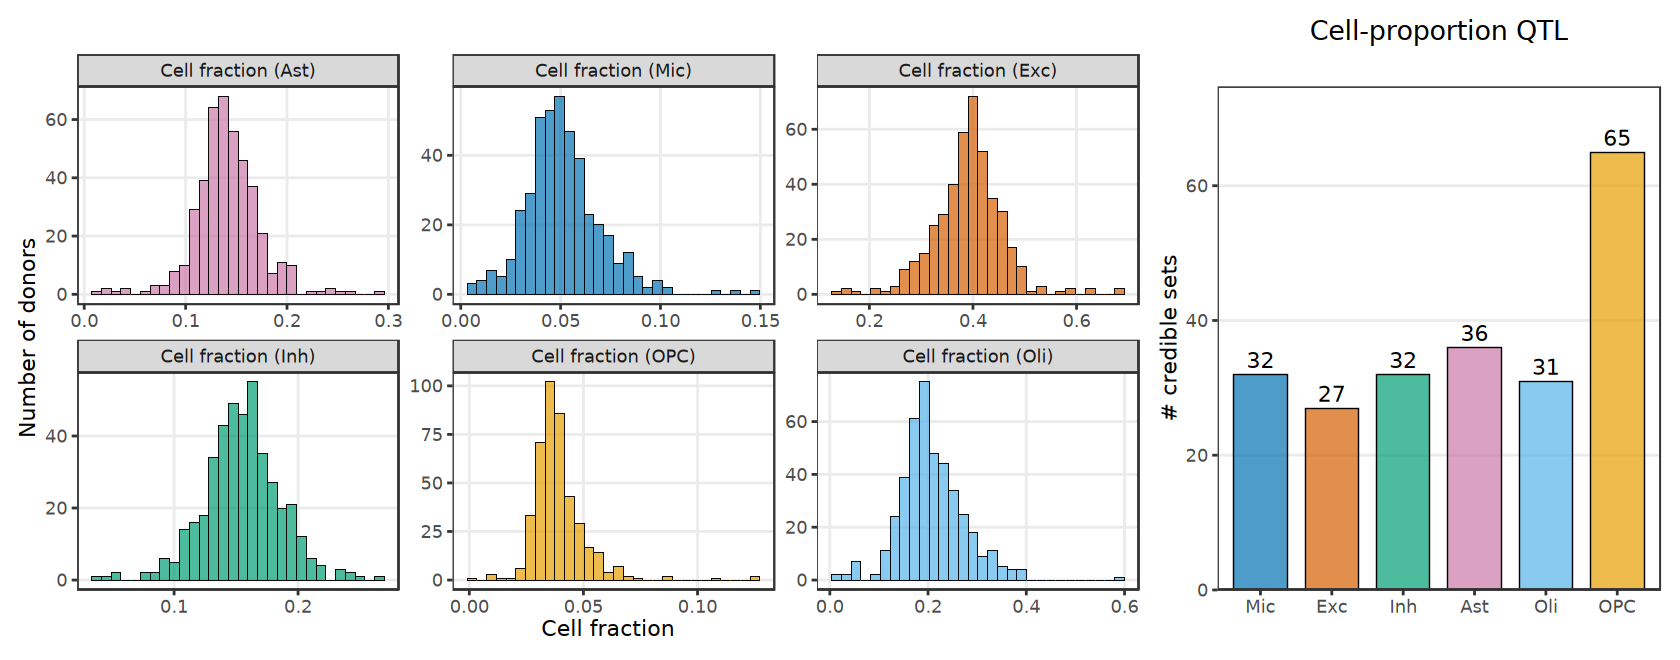

In [2]:
ct_cols <- c(Mic = "#0072B2", Exc = "#D55E00", Inh = "#009E73",
             Ast = "#CC79A7", Oli = "#56B4E9", OPC = "#E69F00")

p_hist <- ggplot(res$histogram) +
  geom_rect(aes(xmin = bin_min, xmax = bin_max, ymin = 0, ymax = n_donors, fill = cell_type),
            colour = "black", linewidth = 0.2, alpha = 0.7) +
  facet_wrap(~ cell_type, nrow = 2, scales = "free",
             labeller = labeller(cell_type = function(x) paste0("Cell fraction (", x, ")"))) +
  scale_fill_manual(values = ct_cols, guide = "none") +
  labs(x = "Cell fraction", y = "Number of donors") +
  theme_bw(base_size = 13) + theme(panel.grid.minor = element_blank())

p_cs <- ggplot(res$propQTL_cs, aes(x = cell_type, y = n_cs, fill = cell_type)) +
  geom_col(width = 0.75, alpha = 0.7, colour = "black", linewidth = 0.3) +
  geom_text(aes(label = n_cs), vjust = -0.4, size = 4.5) +
  scale_fill_manual(values = ct_cols, guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(x = NULL, y = "# credible sets", title = "Cell-proportion QTL") +
  theme_bw(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5), panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank())

options(repr.plot.width = 14, repr.plot.height = 5.5)
p_hist + p_cs + plot_layout(widths = c(2.4, 1))